# Eje 9a — Volatilidad implícita

Derivados Financieros · QUANt UCEMA

Dado un precio de mercado $V^{mkt}$, buscamos $\sigma_{imp}$ tal que
$V_{BS}(S,K,T,r,q,\sigma_{imp})=V^{mkt}$.

**Plan**
1. Idea y bisección
2. `impvolfunc_bs`
3. Smile sintético
4. Resumen

## 1) Setup

In [1]:
import math
import sys
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

print("OK")

OK


In [2]:
from Codigo.pricing import opcion_europea_bs
from Codigo.analytics.vol_implicita import impvolfunc_bs, bisect

## 2) Idea

Invertimos el pricer:

$$
\sigma_{imp} = \arg\min_\sigma \big|V_{model}(\sigma)-V^{mkt}\big|
$$

Con BS la función es monótona en $\sigma$ → **bisección** basta (como en `Codigo.analytics`).

## 3) Ejemplo puntual

In [3]:
tipo = "C"
S, K, T = 100.0, 100.0, 0.5
r, div = 0.05, 0.0
sigma_true = 0.22
precio = opcion_europea_bs(tipo, S, K, T, r, sigma_true, div)
# contaminamos un poco el "mercado"
precio_mkt = precio * 1.01
iv = impvolfunc_bs(tipo, S, K, T, r, precio_mkt, div)
print(f"precio modelo @ {sigma_true:.2%} = {precio:.4f}")
print(f"precio mkt ( +1%)     = {precio_mkt:.4f}")
print(f"IV recuperada         = {iv:.4%}  (true={sigma_true:.2%})")

precio modelo @ 22.00% = 7.4365
precio mkt ( +1%)     = 7.5109
IV recuperada         = 22.2712%  (true=22.00%)


## 4) Bisección a mano (misma idea)

In [4]:
def iv_manual(precio_mkt, low=1e-4, high=3.0, iters=60):
    f = lambda sig: opcion_europea_bs(tipo, S, K, T, r, sig, div) - precio_mkt
    return bisect(f, low, high, iters)

print("manual:", iv_manual(precio_mkt))
print("lib   :", impvolfunc_bs(tipo, S, K, T, r, precio_mkt, div))

manual: 0.22271190376595307
lib   : 0.22271190376595307


## 5) Smile sintético (vols distintas por strike)

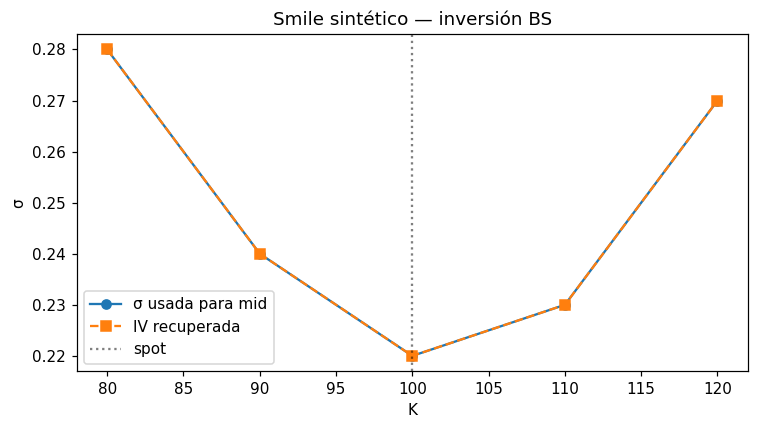

,K,mid,sigma_true,IV
0,80.0,22.850867,0.28,0.28
1,90.0,14.238753,0.24,0.24
2,100.0,7.436538,0.22,0.22
3,110.0,3.691472,0.23,0.23
4,120.0,2.372946,0.27,0.27


In [5]:
strikes = np.array([80, 90, 100, 110, 120], dtype=float)
# smile inventado: mayor vol en alas
sigmas = np.array([0.28, 0.24, 0.22, 0.23, 0.27])
mids = [opcion_europea_bs(tipo, S, k, T, r, sig, div) for k, sig in zip(strikes, sigmas)]
ivs = [impvolfunc_bs(tipo, S, k, T, r, m, div) for k, m in zip(strikes, mids)]

fig, ax = plt.subplots(figsize=(7, 4), dpi=110)
ax.plot(strikes, sigmas, "o-", label="σ usada para mid")
ax.plot(strikes, ivs, "s--", label="IV recuperada")
ax.axvline(S, color="k", ls=":", alpha=0.5, label="spot")
ax.set_xlabel("K"); ax.set_ylabel("σ")
ax.set_title("Smile sintético — inversión BS")
ax.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"K": strikes, "mid": mids, "sigma_true": sigmas, "IV": ivs}).round(6)

## Resumen

- IV es el $\sigma$ que hace coincidir el modelo con el mid de mercado.
- En BS se obtiene por root-finding; en americanas usamos binomial (`impvolfunc_bin`).
- El **smile/skew** aparece porque el mercado no es BS puro: una IV distinta por strike.

**Ejercicio:** construí IVs de puts con los mismos strikes y compará put–call IV ATM.

**Siguiente:** **10a** — Market Data II.